# PFDM 2次元: 直接法 vs CG (スパース性+BTTB+FFT の同時利用)

2次元Poisson方程式に対する $(D_h K D_h^\\top + \\sigma I)\\alpha = b$ を解く：

- **直接法 (Cholesky)**: $D_h K D_h^\\top + \\sigma I$ を明示構築してCholesky $O(N^3)$
- **CG + dense DKD**: $D_h K D_h^\\top + \\sigma I$ を明示構築してCG（行列ベクトル積 $O(N^2)$）
- **CG + スパース + 2D FFT** (提案手法):
  1. $w_1 = D_h^\\top v$ → スパース積 $O(N)$
  2. $w_2 = K w_1$ → 2次元カーネルは BTTB → 2D FFT で $O(N \\log N)$
  3. $w_3 = D_h w_2 + \\sigma v$ → スパース積 $O(N)$

$N = Nx \\times Ny$，CG + dense DKD は $N > 2500$ でスキップ。

In [2]:
using LinearAlgebra
using SparseArrays
using FFTW
using SpecialFunctions
using IterativeSolvers
using LinearMaps
using Plots
using Statistics
using Printf


In [3]:
# 2次元 Matérnカーネル
function matern_kernel_2d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

# 2次元 D_h (スパース, 5点ステンシル)
function build_Dh_2d(Nx, Ny, dx)
    N = Nx * Ny
    index(i, j) = i + (j-1)*Nx
    rows, cols, vals = Int[], Int[], Float64[]
    for j in 1:Ny, i in 1:Nx
        k = index(i, j)
        push!(rows, k); push!(cols, k); push!(vals, -4.0/dx^2)
        if i > 1;  push!(rows, k); push!(cols, index(i-1,j)); push!(vals, 1.0/dx^2); end
        if i < Nx; push!(rows, k); push!(cols, index(i+1,j)); push!(vals, 1.0/dx^2); end
        if j > 1;  push!(rows, k); push!(cols, index(i,j-1)); push!(vals, 1.0/dx^2); end
        if j < Ny; push!(rows, k); push!(cols, index(i,j+1)); push!(vals, 1.0/dx^2); end
    end
    return sparse(rows, cols, vals, N, N)
end

# 2次元 BTTB 行列ベクトル積 (2D FFT)
# 定常カーネル k(x-x') on 均一グリッド → BTTB 構造
# 第1列 (Nx×Ny の行列形式) を循環埋め込みで 2D FFT
function bttb_matvec(k_fft2, v, Nx, Ny)
    # v: 長さ Nx*Ny のベクトル → Nx×Ny 行列に reshape
    V = reshape(v, Nx, Ny)
    # ゼロパディング: (2Nx) × (2Ny)
    V_pad = zeros(2Nx, 2Ny)
    V_pad[1:Nx, 1:Ny] .= V
    # 2D FFT で積
    result = real.(ifft2(k_fft2 .* fft2(V_pad)))
    return vec(result[1:Nx, 1:Ny])
end

# BTTB の FFT 埋め込みを事前計算
# k_col: Nx×Ny の第1列行列 (k(x_i - x_1, y_j - y_1))
function bttb_fft_setup(k_col_mat, Nx, Ny)
    # 循環埋め込み: (2Nx) × (2Ny)
    C = zeros(2Nx, 2Ny)
    C[1:Nx, 1:Ny] .= k_col_mat
    # x方向の折り返し
    if Nx > 1
        C[Nx+2:2Nx, 1:Ny] .= k_col_mat[Nx:-1:2, :]
    end
    # y方向の折り返し
    if Ny > 1
        C[1:Nx, Ny+2:2Ny] .= k_col_mat[:, Ny:-1:2]
    end
    # 両方向の折り返し
    if Nx > 1 && Ny > 1
        C[Nx+2:2Nx, Ny+2:2Ny] .= k_col_mat[Nx:-1:2, Ny:-1:2]
    end
    return fft2(C)
end

fft2  = x -> fft(fft(x, 1), 2)
ifft2 = x -> ifft(ifft(x, 1), 2)

u_exact(x, y) = sin(π*x) * sin(π*y) / (2π^2)
f_func(x, y)  = -sin(π*x) * sin(π*y)


f_func (generic function with 1 method)

In [8]:
ν   = 1.5
ℓ   = 1.0
σf  = 1.0
C   = 1e-3
τ   = 2

# dense DKD-CG を実行するサイズ上限
dense_max_N = 2500

grid_sizes = [5, 8, 10, 15, 20, 30, 50, 60, 70, 80, 90, 100]

results = []

for Nx in grid_sizes
    Ny  = Nx
    N   = Nx * Ny
    dx  = 1.0 / (Nx + 1)

    x = range(dx, step=dx, length=Nx)
    y = range(dx, step=dx, length=Ny)

    X_all  = [[xi, yj] for yj in y for xi in x]
    b_vec  = [f_func(xi, yj)  for yj in y for xi in x]
    u_true = [u_exact(xi, yj) for yj in y for xi in x]

    Dh_sp   = build_Dh_2d(Nx, Ny, dx)
    σ_noise = C * dx^(2τ)

    # BTTB の第1列行列
    k_col_mat = [matern_kernel_2d([x[i], y[j]], [x[1], y[1]]; ν=ν, ℓ=ℓ, σf=σf)
                 for i in 1:Nx, j in 1:Ny]
    k_fft2 = bttb_fft_setup(k_col_mat, Nx, Ny)

    # ===== 直接法 (Cholesky) =====
    t_direct = @elapsed begin
        K     = [matern_kernel_2d(X_all[i], X_all[j]; ν=ν, ℓ=ℓ, σf=σf)
                 for i in 1:N, j in 1:N]
        A     = Dh_sp * K * Dh_sp' + σ_noise * I(N)
        α_dir = cholesky(Hermitian(A)) \ b_vec
        μ_dir = (Dh_sp * K)' * α_dir
    end
    mse_direct = mean((μ_dir .- u_true).^2)

    # ===== CG + dense DKD (competitor) =====
    if N <= dense_max_N
        t_cg_dense = @elapsed begin
            K_dense = [matern_kernel_2d(X_all[i], X_all[j]; ν=ν, ℓ=ℓ, σf=σf)
                       for i in 1:N, j in 1:N]
            DKD = Dh_sp * K_dense * Dh_sp' + σ_noise * I(N)
            α_dense, hist_dense = cg(Hermitian(DKD), b_vec;
                                     log=true, maxiter=50000, reltol=1e-10)
            μ_dense = (Dh_sp * K_dense)' * α_dense
        end
        mse_dense    = mean((μ_dense .- u_true).^2)
        n_iter_dense = hist_dense.iters
    else
        t_cg_dense   = NaN
        mse_dense    = NaN
        n_iter_dense = -1
    end

    # ===== CG + スパース + 2D FFT (提案手法) =====
    A_map = LinearMap(
        v -> begin
            w1 = Dh_sp' * v
            w2 = bttb_matvec(k_fft2, w1, Nx, Ny)
            w3 = Dh_sp * w2
            w3 .+ σ_noise .* v
        end,
        N; issymmetric=true, isposdef=true
    )

    t_cg = @elapsed begin
        α_cg, hist = cg(A_map, b_vec; log=true, maxiter=10000, reltol=1e-10)
        μ_cg = bttb_matvec(k_fft2, Dh_sp' * α_cg, Nx, Ny)
    end
    mse_cg = mean((μ_cg .- u_true).^2)
    n_iter = hist.iters

    push!(results, (
        N=N, Nx=Nx,
        t_direct=t_direct, t_cg_dense=t_cg_dense, t_cg=t_cg,
        mse_direct=mse_direct, mse_dense=mse_dense, mse_cg=mse_cg,
        n_iter=n_iter, n_iter_dense=n_iter_dense
    ))

    dense_str = isnan(t_cg_dense) ? "skipped" :
        @sprintf("%.3gs(iter=%d)", t_cg_dense, n_iter_dense)
    @printf("Nx=%3d (N=%5d): Cholesky=%.3gs  CG_dense=%s  CG_FFT=%.3gs(iter=%d)  MSE=%.3e\n",
        Nx, N, t_direct, dense_str, t_cg, n_iter, mse_cg)
end


Nx=  5 (N=   25): Cholesky=0.019s  CG_dense=0.0192s(iter=8)  CG_FFT=0.0728s(iter=8)  MSE=4.957e-07
Nx=  8 (N=   64): Cholesky=0.000685s  CG_dense=0.000666s(iter=16)  CG_FFT=0.000146s(iter=18)  MSE=8.475e-08
Nx= 10 (N=  100): Cholesky=0.00162s  CG_dense=0.00172s(iter=31)  CG_FFT=0.000369s(iter=29)  MSE=3.616e-08
Nx= 15 (N=  225): Cholesky=0.012s  CG_dense=0.0149s(iter=65)  CG_FFT=0.00653s(iter=66)  MSE=7.564e-09
Nx= 20 (N=  400): Cholesky=0.0296s  CG_dense=0.027s(iter=93)  CG_FFT=0.00585s(iter=99)  MSE=2.466e-09
Nx= 30 (N=  900): Cholesky=0.16s  CG_dense=0.194s(iter=168)  CG_FFT=0.0155s(iter=179)  MSE=5.023e-10
Nx= 50 (N= 2500): Cholesky=1.15s  CG_dense=1.19s(iter=366)  CG_FFT=0.0801s(iter=409)  MSE=6.677e-11
Nx= 60 (N= 3600): Cholesky=2.3s  CG_dense=skipped  CG_FFT=0.192s(iter=541)  MSE=3.241e-11
Nx= 70 (N= 4900): Cholesky=4.23s  CG_dense=skipped  CG_FFT=0.322s(iter=713)  MSE=1.757e-11
Nx= 80 (N= 6400): Cholesky=7.19s  CG_dense=skipped  CG_FFT=0.503s(iter=893)  MSE=1.034e-11
Nx= 90 (N=

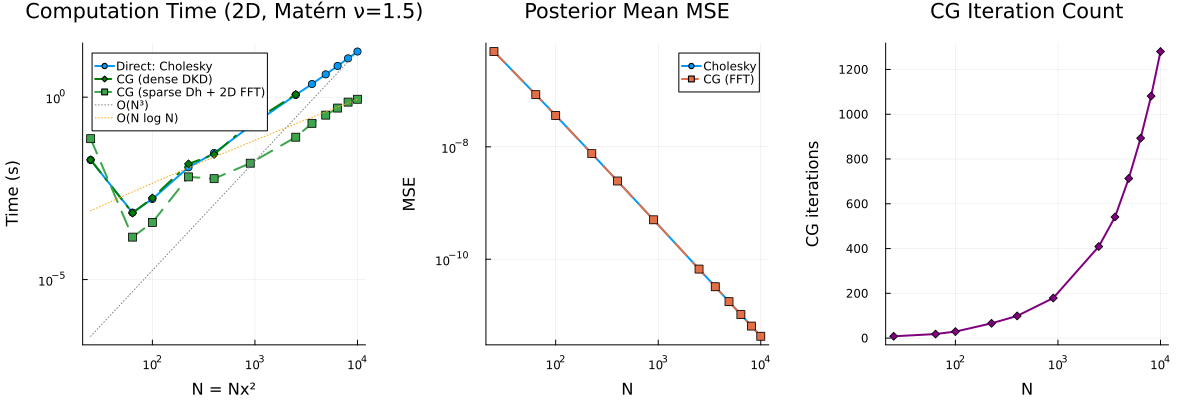

Saved: pfdm_2d_bttb_cg.png


In [9]:
Ns           = [r.N           for r in results]
t_dir        = [r.t_direct    for r in results]
t_cg_dense_v = [r.t_cg_dense  for r in results]
t_cg_v       = [r.t_cg        for r in results]
mse_dir      = [r.mse_direct  for r in results]
mse_cg       = [r.mse_cg      for r in results]
n_iters      = [r.n_iter      for r in results]

# dense が実行されたサイズのみ抽出
mask_dense = .!isnan.(t_cg_dense_v)
Ns_dense   = Ns[mask_dense]
t_dense    = t_cg_dense_v[mask_dense]

p1 = plot(Ns, t_dir;
    marker=:circle, lw=2, label="Direct: Cholesky",
    xlabel="N = Nx²", ylabel="Time (s)", title="Computation Time (2D, Matérn ν=$ν)",
    yscale=:log10, xscale=:log10, legend=:topleft)
plot!(p1, Ns_dense, t_dense;
    marker=:diamond, lw=2, ls=:dashdot, color=:green,
    label="CG (dense DKD)")
plot!(p1, Ns, t_cg_v;
    marker=:square, lw=2, ls=:dash,
    label="CG (sparse Dh + 2D FFT)")
c3 = t_dir[end] / Ns[end]^3
c1 = t_cg_v[end] / (Ns[end] * log(Ns[end]))
plot!(p1, Ns, c3 .* Ns.^3;          lw=1, ls=:dot, color=:gray,   label="O(N³)")
plot!(p1, Ns, c1 .* Ns .* log.(Ns); lw=1, ls=:dot, color=:orange, label="O(N log N)")

p2 = plot(Ns, mse_dir;
    marker=:circle, lw=2, label="Cholesky",
    xlabel="N", ylabel="MSE", title="Posterior Mean MSE",
    yscale=:log10, xscale=:log10, legend=:topright)
plot!(p2, Ns, mse_cg;
    marker=:square, lw=2, ls=:dash, label="CG (FFT)")

p3 = plot(Ns, n_iters;
    marker=:diamond, lw=2, color=:purple,
    xlabel="N", ylabel="CG iterations",
    title="CG Iteration Count",
    xscale=:log10, legend=false)

p_all = plot(p1, p2, p3; layout=(1,3), size=(1200, 400), margin=6Plots.mm)
display(p_all)
savefig(p_all, "pfdm_2d_bttb_cg.png")
println("Saved: pfdm_2d_bttb_cg.png")


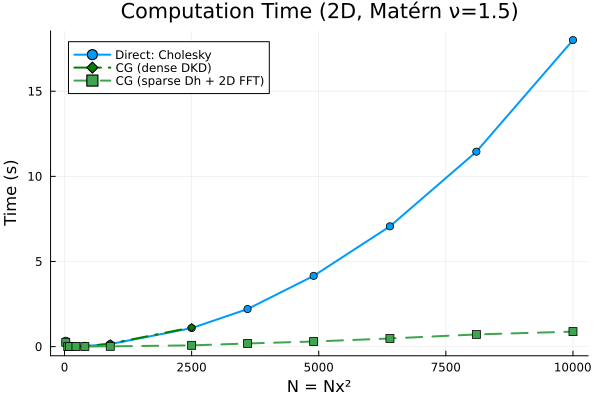

Saved: pfdm_2d_bttb_cg_time.png


In [6]:
# 計算時間のみのシンプルなプロット
p1 = plot(Ns, t_dir;
    marker=:circle, lw=2, label="Direct: Cholesky",
    xlabel="N = Nx²", ylabel="Time (s)", title="Computation Time (2D, Matérn ν=$ν)",
    legend=:topleft)
plot!(p1, Ns_dense, t_dense;
    marker=:diamond, lw=2, ls=:dashdot, color=:green,
    label="CG (dense DKD)")
plot!(p1, Ns, t_cg_v;
    marker=:square, lw=2, ls=:dash,
    label="CG (sparse Dh + 2D FFT)")

display(p1)
savefig(p1, "pfdm_2d_bttb_cg_time.png")
println("Saved: pfdm_2d_bttb_cg_time.png")
